# PTB-XL — CNN + temporal Transformer training

This is a new comparative candidate notebook. The original `ptbxl_cnn_BiLSTM.ipynb`, `ptbxl_cnn_1D.ipynb` and `ptbxl_cnn_resnet.ipynb` are preserved unchanged. This notebook trains the additional CNN + temporal Transformer architecture using the same preprocessed, patient-disjoint PTB-XL manifest.

The complete training, validation, checkpoint selection, held-out test evaluation and artifact export are implemented in notebook cells. `src/` supplies the ECG architecture, dataset loader, reusable loss classes and utilities; no `src.training.train_ecg` command is called.

In [1]:
from pathlib import Path
import json, sys, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, brier_score_loss


def find_ml_service_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").is_dir() and (candidate / "config").is_dir(): return candidate
        if (candidate / "ml-service" / "src").is_dir(): return candidate / "ml-service"
    raise FileNotFoundError("Could not locate ml-service; open the notebook from the repository.")

ML_ROOT = find_ml_service_root()
if str(ML_ROOT) not in sys.path: sys.path.insert(0, str(ML_ROOT))
from src.datasets.ptbxl_loader import build_ptbxl_loaders
from src.models.ecg.ecg_transformer import ECGTransformer
from src.training.losses import MaskedBCEWithLogitsLoss

SEED = 42
PREPROCESSING_VERSION = "100hz_record_zscore"
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 60
PATIENCE = 10
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = ML_ROOT
ARTIFACT_DIR = ML_ROOT / "artifacts" / "metrics" / "ecg" / "ecg_transformer"
CHECKPOINT_DIR = ML_ROOT / "checkpoints" / "ecg" / "ptbxl"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True); CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
print("Device:", DEVICE, "ML root:", ML_ROOT)

Device: cuda ML root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service


## 1. Verify processed manifest, patient-level partitions and target columns

Run `notebooks/02_preprocessing/02_ptbxl_ecg_preprocessing.ipynb` first. It creates the patient-disjoint manifest and normalized 12-lead 100 Hz waveforms. The loader performs split-overlap checks again before DataLoaders are returned.

In [2]:
manifest_path = ML_ROOT / "data" / "processed" / "ecg" / "ptbxl" / PREPROCESSING_VERSION / "manifests" / "ptbxl_manifest.csv"
if not manifest_path.is_file():
    raise FileNotFoundError(f"Processed PTB-XL manifest not found: {manifest_path}. Run the existing PTB-XL preprocessing notebook first.")
manifest = pd.read_csv(manifest_path)
required = {"patient_id", "ecg_id", "split", "processed_path", "NORM", "MI", "STTC", "CD", "HYP"}
missing = sorted(required - set(manifest.columns))
if missing: raise ValueError(f"PTB-XL manifest missing required columns: {missing}")
print("Manifest shape:", manifest.shape)
display(manifest["split"].value_counts().rename_axis("split").to_frame("records"))

patient_sets = {name: set(manifest.loc[manifest["split"] == name, "patient_id"].dropna()) for name in ["train", "val", "test"]}
overlap = {"train_val": len(patient_sets["train"] & patient_sets["val"]),
           "train_test": len(patient_sets["train"] & patient_sets["test"]),
           "val_test": len(patient_sets["val"] & patient_sets["test"])}
print("Patient overlap:", overlap)
if any(overlap.values()): raise RuntimeError("Patient leakage exists. Do not train until the split manifest is corrected.")

loaders = build_ptbxl_loaders(data_root=ML_ROOT, batch_size=BATCH_SIZE, seed=SEED,
                               preprocessing_version=PREPROCESSING_VERSION, num_workers=NUM_WORKERS,
                               pin_memory=(DEVICE.type == "cuda"))
diagnostic_targets = list(loaders["diagnostic_targets"])
rhythm_targets = list(loaders["rhythm_targets"])
if not diagnostic_targets: raise ValueError("No diagnostic labels available in PTB-XL manifest.")
print("Diagnostic targets:", diagnostic_targets)
print("Rhythm targets:", rhythm_targets)
print("Split sizes:", {name: len(loaders[name].dataset) for name in ["train", "val", "test"]})

Manifest shape: (21837, 25)


,records
split,
train,17441
test,2203
val,2193


Patient overlap: {'train_val': 0, 'train_test': 0, 'val_test': 0}
Diagnostic targets: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Rhythm targets: ['RHYTHM_SR', 'RHYTHM_AFIB', 'RHYTHM_AFLT', 'RHYTHM_STACH', 'RHYTHM_SBRAD', 'RHYTHM_SARRH', 'RHYTHM_PSVT', 'RHYTHM_BIGU', 'RHYTHM_PACE']
Split sizes: {'train': 17441, 'val': 2193, 'test': 2203}


## 2. Define model, masked multi-label loss and epoch routines

The model outputs raw logits. Diagnostic and rhythm targets are independent multi-label outputs and use sigmoid/BCE, not softmax. The test partition is not used for early stopping or threshold selection.

In [3]:
MODEL_CONFIG = {
    "num_leads": 12,
    "num_diagnostic_classes": len(diagnostic_targets),
    "num_rhythm_classes": len(rhythm_targets),
    "cnn_channels": 96,
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 3,
    "dropout": 0.20,
    "max_tokens": 250,
}
model = ECGTransformer(**MODEL_CONFIG).to(DEVICE)
criterion = MaskedBCEWithLogitsLoss()
task_weights = {"diagnostic": 1.0, "rhythm": 1.0}
if not rhythm_targets: task_weights.pop("rhythm")
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-7)


def batch_targets(batch):
    targets = {}
    masks = {}
    for name in ["diagnostic", "rhythm"]:
        if name == "rhythm" and not rhythm_targets: continue
        value = batch["targets"][name].to(DEVICE).float()
        mask = torch.isfinite(value).float()
        targets[name] = torch.nan_to_num(value, nan=0.0)
        masks[name] = mask
    return targets, masks


def forward_logits(signal):
    output = model(signal)
    return {name: output[name] for name in task_weights}


def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0; batches = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch in loader:
            signal = batch["signal"].to(DEVICE, non_blocking=True).float()
            targets, masks = batch_targets(batch)
            if training: optimizer.zero_grad(set_to_none=True)
            logits = forward_logits(signal)
            task_losses = []
            for task in task_weights:
                loss = criterion(logits[task], targets[task], masks[task])
                task_losses.append(loss * task_weights[task])
            loss = torch.stack(task_losses).sum()
            if not torch.isfinite(loss): raise FloatingPointError("Non-finite ECG loss.")
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                optimizer.step()
            total_loss += float(loss.detach().cpu()); batches += 1
    if batches == 0: raise RuntimeError("No PTB-XL batches were processed.")
    return total_loss / batches

## 3. Train, select using validation loss and restore best weights

In [4]:
history = []
best_val_loss = float("inf"); best_state = None; best_epoch = 0; stale_epochs = 0
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(loaders["train"], training=True)
    val_loss = run_epoch(loaders["val"], training=False)
    scheduler.step(val_loss)
    history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss,
                    "learning_rate": float(optimizer.param_groups[0]["lr"])})
    print(f"Epoch {epoch:03d}/{EPOCHS} | train={train_loss:.5f} | validation={val_loss:.5f}")
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss; best_epoch = epoch; stale_epochs = 0
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print(f"Early stopping; best epoch {best_epoch}.")
            break
if best_state is None: raise RuntimeError("No best validation checkpoint was produced.")
model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
display(history_df.tail())

Epoch 001/60 | train=0.57409 | validation=0.44901
Epoch 002/60 | train=0.43035 | validation=0.41881
Epoch 003/60 | train=0.39554 | validation=0.39187
Epoch 004/60 | train=0.37435 | validation=0.39330
Epoch 005/60 | train=0.35610 | validation=0.38262
Epoch 006/60 | train=0.34187 | validation=0.37924
Epoch 007/60 | train=0.33216 | validation=0.38694
Epoch 008/60 | train=0.32099 | validation=0.40185
Epoch 009/60 | train=0.30868 | validation=0.38327
Epoch 010/60 | train=0.30036 | validation=0.38223
Epoch 011/60 | train=0.27456 | validation=0.40323
Epoch 012/60 | train=0.26384 | validation=0.39263
Epoch 013/60 | train=0.25715 | validation=0.40458
Epoch 014/60 | train=0.24997 | validation=0.40388
Epoch 015/60 | train=0.23085 | validation=0.43283
Epoch 016/60 | train=0.22103 | validation=0.44317
Early stopping; best epoch 6.


,epoch,train_loss,validation_loss,learning_rate
11,12,0.263845,0.392628,0.000050
12,13,0.257155,0.404583,0.000050
13,14,0.249974,0.403880,0.000025
14,15,0.230849,0.432827,0.000025
15,16,0.221034,0.443171,0.000025


## 4. Export validation and test predictions, metrics and checkpoint

Validation predictions are retained for calibration. Test predictions are reserved for final evaluation only. Each row identifies a recording and has per-label probabilities; those probabilities represent PTB-XL annotation estimates, not a unified clinical disease probability.

In [5]:
def predict_dataframe(loader, split_name):
    model.eval(); rows = []
    with torch.no_grad():
        for batch in loader:
            signal = batch["signal"].to(DEVICE, non_blocking=True).float()
            output = model(signal)
            diagnostic_prob = torch.sigmoid(output["diagnostic"]).cpu().numpy()
            diagnostic_true = batch["targets"]["diagnostic"].cpu().numpy()
            rhythm_prob = torch.sigmoid(output["rhythm"]).cpu().numpy() if rhythm_targets else np.empty((len(signal), 0))
            rhythm_true = batch["targets"]["rhythm"].cpu().numpy() if rhythm_targets else np.empty((len(signal), 0))
            paths = batch.get("record_path", [None] * len(signal))
            for i in range(len(signal)):
                row = {"record_path": str(paths[i]), "split": split_name}
                for j, target in enumerate(diagnostic_targets):
                    row[f"{target}_true"] = float(diagnostic_true[i, j])
                    row[f"{target}_prob"] = float(diagnostic_prob[i, j])
                for j, target in enumerate(rhythm_targets):
                    row[f"{target}_true"] = float(rhythm_true[i, j])
                    row[f"{target}_prob"] = float(rhythm_prob[i, j])
                rows.append(row)
    return pd.DataFrame(rows)


def multilabel_metrics(frame, targets):
    output = {}
    for target in targets:
        y = pd.to_numeric(frame[f"{target}_true"], errors="coerce").to_numpy(dtype=float)
        p = pd.to_numeric(frame[f"{target}_prob"], errors="coerce").to_numpy(dtype=float)
        valid = np.isfinite(y) & np.isfinite(p)
        y, p = y[valid].astype(int), p[valid]
        if len(y) == 0 or len(np.unique(y)) < 2:
            output[target] = {"status": "not_computable_single_class_or_no_rows", "n": int(len(y))}
            continue
        output[target] = {"status": "computed", "n": int(len(y)),
                          "auroc": float(roc_auc_score(y, p)),
                          "auprc": float(average_precision_score(y, p)),
                          "brier": float(brier_score_loss(y, p)),
                          "f1_at_0_5": float(f1_score(y, p >= 0.5, zero_division=0)),
                          "precision_at_0_5": float(precision_score(y, p >= 0.5, zero_division=0)),
                          "recall_at_0_5": float(recall_score(y, p >= 0.5, zero_division=0))}
    return output

val_predictions = predict_dataframe(loaders["val"], "validation")
test_predictions = predict_dataframe(loaders["test"], "test")
val_predictions.to_csv(ARTIFACT_DIR / "ptbxl_val_predictions.csv", index=False)
test_predictions.to_csv(ARTIFACT_DIR / "ptbxl_test_predictions.csv", index=False)
history_df.to_csv(ARTIFACT_DIR / "training_history.csv", index=False)

metrics = {
    "architecture": "ecg_transformer", "dataset": "PTB-XL", "preprocessing_version": PREPROCESSING_VERSION,
    "best_epoch": best_epoch, "best_validation_loss": best_val_loss,
    "validation": {"diagnostic": multilabel_metrics(val_predictions, diagnostic_targets),
                   "rhythm": multilabel_metrics(val_predictions, rhythm_targets)},
    "test": {"diagnostic": multilabel_metrics(test_predictions, diagnostic_targets),
             "rhythm": multilabel_metrics(test_predictions, rhythm_targets)},
    "patient_disjoint_split_verified": True,
}
checkpoint = {
    "format_version": 2, "architecture": "ecg_transformer", "model_state_dict": model.state_dict(),
    "model_config": MODEL_CONFIG, "num_leads": 12,
    "diagnostic_targets": diagnostic_targets, "rhythm_targets": rhythm_targets,
    "sampling_rate": 100, "signal_length": 1000,
    "preprocessing_version": PREPROCESSING_VERSION,
    "best_epoch": best_epoch, "best_validation_loss": best_val_loss,
    "patient_disjoint_split": True,
}
checkpoint_path = CHECKPOINT_DIR / "ptbxl_ecg_transformer.pt"
torch.save(checkpoint, checkpoint_path)
np.save(ARTIFACT_DIR / "ecg_background_signals.npy", next(iter(loaders["train"]))["signal"][:min(32, BATCH_SIZE)].numpy().astype(np.float32))
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Checkpoint:", checkpoint_path)
print(json.dumps(metrics, indent=2))

Checkpoint: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\ecg\ptbxl\ptbxl_ecg_transformer.pt
{
  "architecture": "ecg_transformer",
  "dataset": "PTB-XL",
  "preprocessing_version": "100hz_record_zscore",
  "best_epoch": 6,
  "best_validation_loss": 0.37924236469510675,
  "validation": {
    "diagnostic": {
      "NORM": {
        "status": "computed",
        "n": 2193,
        "auroc": 0.9465550212537156,
        "auprc": 0.927010922044278,
        "brier": 0.09829296367686877,
        "f1_at_0_5": 0.8523328523328524,
        "precision_at_0_5": 0.7896613190730838,
        "recall_at_0_5": 0.9258098223615465
      },
      "MI": {
        "status": "computed",
        "n": 2193,
        "auroc": 0.9109570639960047,
        "auprc": 0.8071857441557861,
        "brier": 0.10430294669893363,
        "f1_at_0_5": 0.6184834123222749,
        "precision_at_0_5": 0.87,
        "recall_at_0_5": 0.4797794117647059
      },
      "STTC": {
        "status": "computed"

## 5. Training history and label-wise performance plots

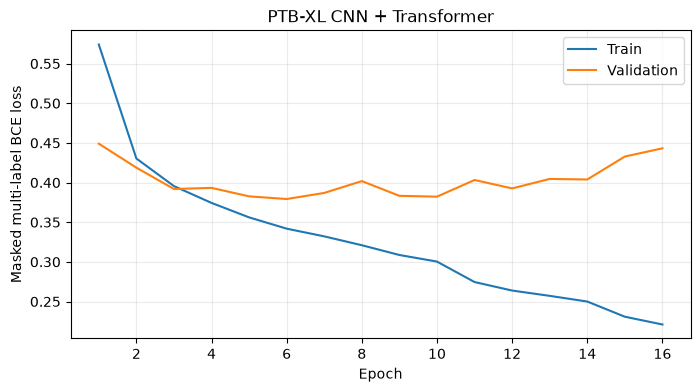

,group,label,status,n,auroc,auprc,brier,f1_at_0_5,precision_at_0_5,recall_at_0_5
0,diagnostic,NORM,computed,2203,0.943319,0.920549,0.105359,0.850070,0.773152,0.943983
1,diagnostic,MI,computed,2203,0.898496,0.778889,0.114385,0.589623,0.847458,0.452080
2,diagnostic,STTC,computed,2203,0.932655,0.809994,0.083507,0.765336,0.779762,0.751434
3,diagnostic,CD,computed,2203,0.904365,0.800831,0.087145,0.710900,0.867052,0.602410
4,diagnostic,HYP,computed,2203,0.897333,0.653716,0.065824,0.614737,0.688679,0.555133
5,rhythm,RHYTHM_SR,computed,2203,0.833966,0.920751,0.116373,0.908788,0.851929,0.973778
6,rhythm,RHYTHM_AFIB,computed,2203,0.969864,0.752221,0.027779,0.722973,0.743056,0.703947
7,rhythm,RHYTHM_AFLT,computed,2203,0.928311,0.118432,0.003004,0.000000,0.000000,0.000000
8,rhythm,RHYTHM_STACH,computed,2203,0.983878,0.730559,0.019145,0.571429,0.818182,0.439024
9,rhythm,RHYTHM_SBRAD,computed,2203,0.926470,0.324882,0.023112,0.162162,0.600000,0.093750


In [6]:
plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Masked multi-label BCE loss"); plt.title("PTB-XL CNN + Transformer")
plt.grid(alpha=0.25); plt.legend(); plt.show()

label_metrics = []
for group_name, label_list in [("diagnostic", diagnostic_targets), ("rhythm", rhythm_targets)]:
    values = multilabel_metrics(test_predictions, label_list)
    for label, result in values.items(): label_metrics.append({"group": group_name, "label": label, **result})
label_metrics_df = pd.DataFrame(label_metrics)
display(label_metrics_df)
label_metrics_df.to_csv(ARTIFACT_DIR / "test_metrics_per_label.csv", index=False)

## 6. Comparison contract and scientific limitations

Compare this model against the original CNN-BiLSTM-Attention notebook using the same PTB-XL preprocessing version, patient-disjoint partitions, label definitions and metrics. Model selection should use validation results; the held-out test split must not be repeatedly used to tune architecture or thresholds.

This Transformer is an **ECG-only** model. It does not perform cross-modal attention over the biomarker and echocardiography branches. The six project datasets are unpaired, so no such patient-level attention can be trained from them.